# 7 — One galaxy at a time: MW, LMC, SMC

Every pooled result so far has to fight the galaxy–age confound: LMC clusters are young (none
above log age 8.8), MW clusters span 6.4–10.1. Restricting to **one galaxy** removes that
confound by construction, and asks where the weak pooled signal (notebooks 1 and 6) comes from.

Subsets, each analysed identically:

| subset | why |
|---|---|
| **MW** | widest age range (3.7 dex); the cleanest test, but distance/extinction vary within it |
| **LMC** | most clusters, narrowest age range (2 dex); every cluster at one distance |
| **SMC** | one distance, intermediate age range |
| **LMC + SMC** | the Magellanic Clouds together (origin kept as a nuisance) |
| **all (pooled)** | the same code on all 348 clusters, as the reference |

Three tests per subset, all with nuisances = cadence, sectors, length, noise floor, brightness,
radius, dec, galactic latitude (plus galaxy where the subset has more than one):

1. **Partial Spearman** per feature family, with a cluster-bootstrap 95% CI (notebook 1).
2. **Residualized ridge**: features regressed on the nuisances inside each fold, then a ridge
   predicts log age; plus the linear nested gain, nuisances + raw − nuisances (notebook 6).
3. **Nested random forest**: ΔR² = full − nuisance-only (notebook 2).

**Nulls.** Tests 2 and 3 use **Freedman–Lane**: age is split into its OLS fit on the nuisances
plus a residual, and only the residual is permuted. That keeps every (linear) age–nuisance relation
inside the subset, which a plain shuffle would break.

**No holdout here.** With ~100 clusters per galaxy a 20% holdout is ~20 clusters, whose R² is
too noisy to read. Repeated 5-fold CV on the whole subset is the only score, so these numbers
are for comparing subsets, not for quoting as final performance.

**Sample size.** Single-galaxy subsets are ~1/3 of the pooled sample, so every interval is about
√3 wider. A null in one galaxy is weak evidence on its own; agreement in sign across galaxies is
what to look for.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import analysis_utils as A

from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

GT = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data'
TABLE = f'{GT}/cluster_table_Sep23_all_combos_le3sectors.pkl'
SEED = 0
N_PERM_LIN = 300      # Freedman-Lane draws for the linear tests (cheap)
N_PERM_RF = 100       # ... for the forest (each draw is a full CV)
N_JOBS = 12
print('using', os.path.basename(TABLE))
pd.set_option('display.width', 220)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
COL = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a', 'LMC + SMC': '#e87ba4', 'all (pooled)': '#0b0b0b'}

using cluster_table_Sep23_all_combos_le3sectors.pkl


In [2]:
rows = A.load_rows(TABLE)
meta = A.cluster_metadata()
clusters = A.cluster_table(rows, meta=meta)
clusters = clusters[clusters.age.notna()].reset_index(drop=True)
reliability = A.feature_reliability(rows)
del rows

FEATURES  = [c for c, _, _ in A.feature_columns(clusters)]
NUISANCES = [n for n, _, _ in A.NUISANCE_SPEC if n in clusters.columns]
# Families are defined ONCE on the full sample (age-free), so every subset tests the same quantities.
clusters, families, FAM_COLS = A.build_family_table(clusters, FEATURES, threshold=0.8,
                                                    reliability=reliability)

SUBSETS = {'MW': ['MW'], 'LMC': ['LMC'], 'SMC': ['SMC'],
           'LMC + SMC': ['LMC', 'SMC'], 'all (pooled)': ['MW', 'LMC', 'SMC']}

def subset(name):
    gals = SUBSETS[name]
    d = clusters[clusters.origin.isin(gals)].reset_index(drop=True)
    nuis = [n for n in NUISANCES if n != 'origin' or len(gals) > 1]
    return d, nuis

summary = pd.DataFrame([dict(subset=k, n=len(subset(k)[0]),
                             age_min=subset(k)[0].age.min(), age_med=subset(k)[0].age.median(),
                             age_max=subset(k)[0].age.max(), age_sd=subset(k)[0].age.std(),
                             n_nuisance_cols=A.design_matrix(*subset(k), add_const=False).shape[1])
                        for k in SUBSETS]).set_index('subset')
display(summary.round(2))

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409


,n,age_min,age_med,age_max,age_sd,n_nuisance_cols
subset,,,,,,
MW,124,6.40,8.53,10.10,0.86,8
LMC,118,6.80,7.90,8.80,0.45,8
SMC,106,7.07,8.20,10.02,0.66,8
LMC + SMC,224,6.80,8.04,10.02,0.59,9
all (pooled),348,6.40,8.10,10.10,0.72,10


## 1 · Partial Spearman per family, within each subset

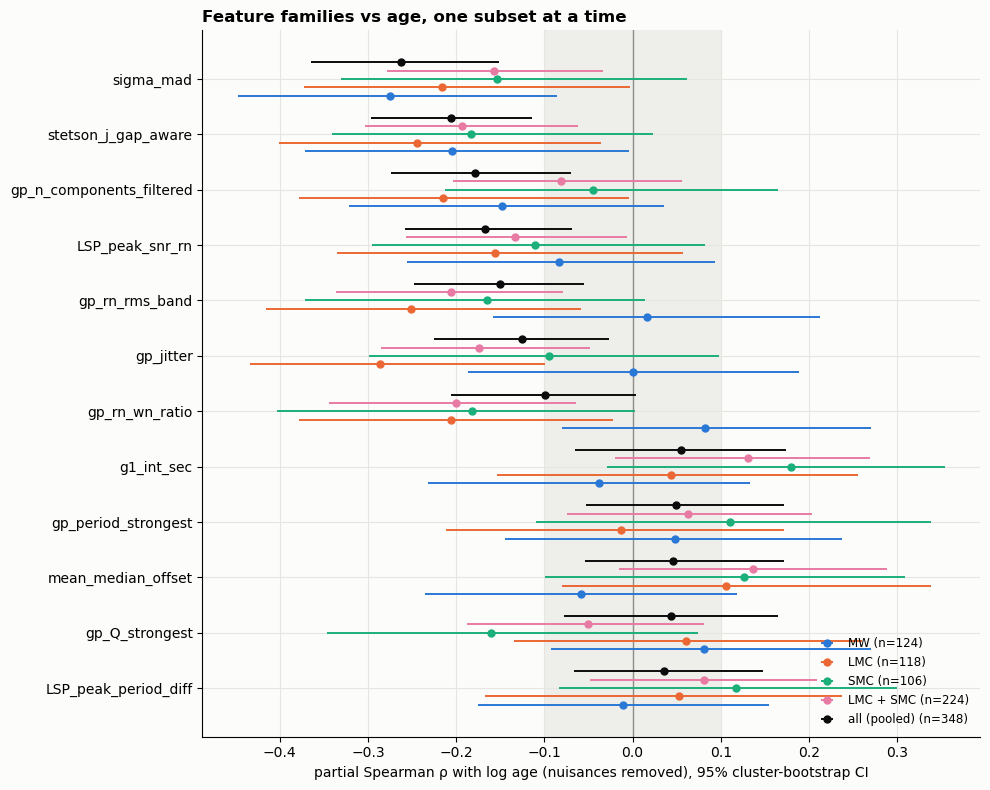

subset,MW,LMC,SMC,LMC + SMC,all (pooled)
family,,,,,
sigma_mad,-0.28 *,-0.22,-0.15,-0.16,-0.26 *
stetson_j_gap_aware,-0.2,-0.24 *,-0.18,-0.19 *,-0.21 *
gp_n_components_filtered,-0.15,-0.21,-0.04,-0.08,-0.18 *
LSP_peak_snr_rn,-0.08,-0.16,-0.11,-0.13,-0.17 *
gp_rn_rms_band,0.02,-0.25 *,-0.17,-0.21 *,-0.15 *
gp_jitter,0.0,-0.29 *,-0.09,-0.17 *,-0.13 *
gp_rn_wn_ratio,0.08,-0.21,-0.18,-0.2 *,-0.1
g1_int_sec,-0.04,0.04,0.18,0.13,0.05
gp_period_strongest,0.05,-0.01,0.11,0.06,0.05


* = FDR < 0.05 within that subset
CONCLUSION —
  MW             1 of 12 families significant; strongest sigma_mad 0.28
  LMC            3 of 12 families significant; strongest gp_jitter 0.29
  SMC            0 of 12 families significant
  LMC + SMC      4 of 12 families significant; strongest gp_rn_rms_band 0.21
  all (pooled)   6 of 12 families significant; strongest sigma_mad 0.26
  Same sign in MW, LMC and SMC as pooled: sigma_mad, stetson_j_gap_aware, gp_n_components_filtered, LSP_peak_snr_rn.


In [3]:
lin = []
for name in SUBSETS:
    d, nuis = subset(name)
    for col in FAM_COLS:
        rho, p, (lo, hi), n = A.partial_spearman_ci(d, col, 'age', nuis, n_boot=1000, seed=SEED)
        lin.append(dict(subset=name, family=col.replace('FAM_', ''), n=n, rho_partial=rho, lo=lo, hi=hi, p=p))
lin = pd.DataFrame(lin)
lin['p_fdr'] = lin.groupby('subset').p.transform(lambda s: A.bh_fdr(s.fillna(1)))
order = (lin[lin.subset == 'all (pooled)'].set_index('family').rho_partial.abs()
         .sort_values(ascending=False).index.tolist())

fig, ax = plt.subplots(figsize=(10, 8))
offs = dict(zip(SUBSETS, np.linspace(-.3, .3, len(SUBSETS))))
ax.axvspan(-.1, .1, color='#e6e5e0', alpha=.6, lw=0, zorder=0)
ax.axvline(0, color='#8f8e88', lw=1)
for name in SUBSETS:
    t = lin[lin.subset == name].set_index('family').reindex(order)
    yy = np.arange(len(order))[::-1] + offs[name]
    ax.errorbar(t.rho_partial, yy, xerr=[t.rho_partial - t.lo, t.hi - t.rho_partial], fmt='o', ms=5,
                color=COL[name], elinewidth=1.4, capsize=0,
                label=f'{name} (n={summary.loc[name, "n"]})')
ax.set_yticks(np.arange(len(order))[::-1], order)
ax.set_xlabel('partial Spearman ρ with log age (nuisances removed), 95% cluster-bootstrap CI')
ax.set_title('Feature families vs age, one subset at a time', loc='left', fontweight='bold')
ax.legend(loc='lower right', fontsize=8.5)
plt.tight_layout(); plt.show()

piv = lin.pivot(index='family', columns='subset', values='rho_partial').reindex(order)[list(SUBSETS)]
sig = lin.pivot(index='family', columns='subset', values='p_fdr').reindex(order)[list(SUBSETS)]
display(piv.round(2).astype(str) + sig.map(lambda q: ' *' if q < 0.05 else ''))
print('* = FDR < 0.05 within that subset')

print('CONCLUSION —')
for name in SUBSETS:
    s = lin[(lin.subset == name) & (lin.p_fdr < 0.05)]
    print(f'  {name:<13} {len(s):2d} of {len(FAM_COLS)} families significant'
          + (f'; strongest {s.loc[s.rho_partial.abs().idxmax(), "family"]} '
             f'{s.rho_partial.abs().max():.2f}' if len(s) else ''))
same_sign = [f for f in order if (np.sign(piv.loc[f, ['MW', 'LMC', 'SMC']]) == np.sign(piv.loc[f, 'all (pooled)'])).all()]
print(f'  Same sign in MW, LMC and SMC as pooled: {", ".join(same_sign) if same_sign else "none"}.')

## 2 · Residualized ridge and the linear nested gain

Same models as notebook 6, 5-fold × 5 repeats on the whole subset, Freedman–Lane null.

In [4]:
def ridge():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 30)))

LIN_MODELS = {
    'nuisance-only':      lambda nn: ('nuis', make_pipeline(SimpleImputer(strategy='median'), ridge())),
    'nuisances + raw':    lambda nn: ('both', make_pipeline(SimpleImputer(strategy='median'), ridge())),
    'residualized → age': lambda nn: ('both', make_pipeline(A.NuisanceResidualizer(nn), ridge())),
}

def lin_cv(Xn, Xb, y, cv):
    nn = Xn.shape[1]
    out = {m: [] for m in LIN_MODELS}
    for tr, te in cv:
        for m, make in LIN_MODELS.items():
            cols, est = make(nn)
            X = Xn if cols == 'nuis' else Xb
            out[m].append(r2_score(y[te], est.fit(X[tr], y[tr]).predict(X[te])))
    return {k: np.array(v) for k, v in out.items()}

def lin_stats(f):
    return {'resid': f['residualized → age'].mean(),
            'gain': (f['nuisances + raw'] - f['nuisance-only']).mean()}

lin_res, lin_null = {}, {}
for name in SUBSETS:
    d, nuis = subset(name)
    Xn = A.design_matrix(d, nuis, add_const=False).to_numpy(float)
    Xb = np.column_stack([Xn, d[FEATURES].apply(pd.to_numeric, errors='coerce').to_numpy(float)])
    y = d.age.to_numpy(float)
    cv = list(RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(Xn))
    lin_res[name] = lin_cv(Xn, Xb, y, cv)
    draw = A.freedman_lane_sampler(Xn, y, seed=SEED)
    lin_null[name] = pd.DataFrame(Parallel(n_jobs=N_JOBS)(
        delayed(lambda yp: lin_stats(lin_cv(Xn, Xb, yp, cv)))(draw()) for _ in range(N_PERM_LIN)))
    print(f'{name:<13} done', flush=True)

rows_ = []
for name in SUBSETS:
    f, nd = lin_res[name], lin_null[name]
    st = lin_stats(f)
    rows_.append(dict(subset=name, n=summary.loc[name, 'n'],
                      r2_nuisance=f['nuisance-only'].mean(), r2_nuis_raw=f['nuisances + raw'].mean(),
                      r2_resid=st['resid'], r2_resid_sd=f['residualized → age'].std(),
                      p_resid=(np.sum(nd.resid >= st['resid']) + 1) / (len(nd) + 1),
                      gain=st['gain'], gain_sd=(f['nuisances + raw'] - f['nuisance-only']).std(),
                      p_gain=(np.sum(nd.gain >= st['gain']) + 1) / (len(nd) + 1),
                      null_resid=nd.resid.mean(), null_gain=nd.gain.mean()))
lin_tab = pd.DataFrame(rows_).set_index('subset')
display(lin_tab.round(3))

MW            done


LMC           done


SMC           done


LMC + SMC     done


all (pooled)  done


,n,r2_nuisance,r2_nuis_raw,r2_resid,r2_resid_sd,p_resid,gain,gain_sd,p_gain,null_resid,null_gain
subset,,,,,,,,,,,
MW,124,-0.090,-0.038,-0.038,0.130,0.060,0.052,0.087,0.023,-0.073,-0.026
LMC,118,0.475,0.482,-0.037,0.047,0.080,0.006,0.090,0.023,-0.062,-0.085
SMC,106,-0.098,-0.132,-0.119,0.139,0.963,-0.033,0.277,0.090,-0.070,-0.134
LMC + SMC,224,0.316,0.345,-0.035,0.062,0.578,0.030,0.071,0.003,-0.034,-0.064
all (pooled),348,0.072,0.125,0.007,0.091,0.003,0.053,0.069,0.003,-0.020,-0.032


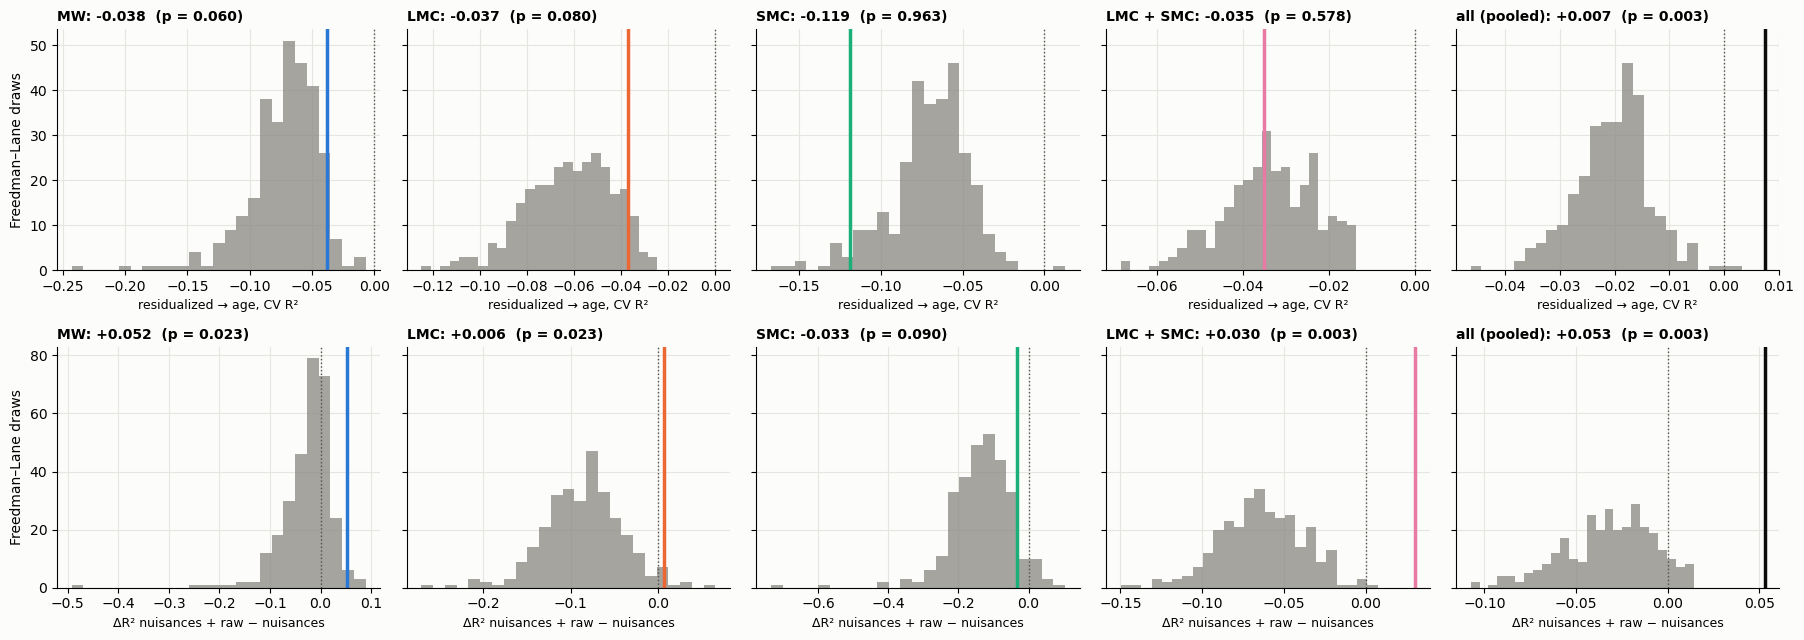

CONCLUSION —
  MW            residualized R² -0.038 ± 0.130 (p = 0.060) | linear gain +0.052 ± 0.087 (p = 0.023)
  LMC           residualized R² -0.037 ± 0.047 (p = 0.080) | linear gain +0.006 ± 0.090 (p = 0.023)
  SMC           residualized R² -0.119 ± 0.139 (p = 0.963) | linear gain -0.033 ± 0.277 (p = 0.090)
  LMC + SMC     residualized R² -0.035 ± 0.062 (p = 0.578) | linear gain +0.030 ± 0.071 (p = 0.003)
  all (pooled)  residualized R² +0.007 ± 0.091 (p = 0.003) | linear gain +0.053 ± 0.069 (p = 0.003)


In [5]:
fig, axes = plt.subplots(2, len(SUBSETS), figsize=(18, 6.5), sharey='row')
for j, name in enumerate(SUBSETS):
    for i, (key, obs_col, lab) in enumerate([('resid', 'r2_resid', 'residualized → age, CV R²'),
                                            ('gain', 'gain', 'ΔR² nuisances + raw − nuisances')]):
        ax = axes[i, j]
        nd = lin_null[name][key]
        o = lin_tab.loc[name, obs_col]
        p = lin_tab.loc[name, 'p_resid' if key == 'resid' else 'p_gain']
        ax.hist(nd, bins=25, color='#8f8e88', alpha=.8)
        ax.axvline(o, color=COL[name], lw=2.5)
        ax.axvline(0, color='#52514e', lw=1, ls=':')
        ax.set_title(f'{name}: {o:+.3f}  (p = {p:.3f})', loc='left', fontweight='bold', fontsize=10)
        ax.set_xlabel(lab, fontsize=9)
axes[0, 0].set_ylabel('Freedman–Lane draws'); axes[1, 0].set_ylabel('Freedman–Lane draws')
plt.tight_layout(); plt.show()

print('CONCLUSION —')
for name, r in lin_tab.iterrows():
    print(f'  {name:<13} residualized R² {r.r2_resid:+.3f} ± {r.r2_resid_sd:.3f} (p = {r.p_resid:.3f}) | '
          f'linear gain {r.gain:+.3f} ± {r.gain_sd:.3f} (p = {r.p_gain:.3f})')

## 3 · Nested random forest

Same forest as notebook 2 (600 trees, `min_samples_leaf=3`, `max_features='sqrt'`). Observed
ΔR² from 5 × 5 CV; the Freedman–Lane null uses 5 × 2 CV per draw to keep the cost down, so the
observed value is also recomputed on that 5 × 2 scheme for the p-value.

In [6]:
def forest(seed, n_jobs=1):
    return make_pipeline(SimpleImputer(strategy='median'),
                         RandomForestRegressor(n_estimators=600, min_samples_leaf=3, max_features='sqrt',
                                               random_state=seed, n_jobs=n_jobs))

def rf_cv(Xn, Xb, y, cv, n_jobs=1):
    rn, rf = [], []
    for k, (tr, te) in enumerate(cv):
        rn.append(r2_score(y[te], forest(SEED + k, n_jobs).fit(Xn[tr], y[tr]).predict(Xn[te])))
        rf.append(r2_score(y[te], forest(SEED + k, n_jobs).fit(Xb[tr], y[tr]).predict(Xb[te])))
    return np.array(rn), np.array(rf)

rf_rows, rf_null = [], {}
for name in SUBSETS:
    d, nuis = subset(name)
    Xn = A.design_matrix(d, nuis, add_const=False).to_numpy(float)
    Xb = np.column_stack([Xn, d[FEATURES].apply(pd.to_numeric, errors='coerce').to_numpy(float)])
    y = d.age.to_numpy(float)
    cv25 = list(RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(Xn))
    cv10 = cv25[:10]
    rn, rf = rf_cv(Xn, Xb, y, cv25, n_jobs=N_JOBS)
    rn10, rf10 = rn[:10], rf[:10]
    draw = A.freedman_lane_sampler(Xn, y, seed=SEED)
    null = np.array(Parallel(n_jobs=N_JOBS)(
        delayed(lambda yp: np.subtract(*rf_cv(Xn, Xb, yp, cv10)[::-1]).mean())(draw())
        for _ in range(N_PERM_RF)))
    rf_null[name] = null
    obs10 = (rf10 - rn10).mean()
    rf_rows.append(dict(subset=name, n=len(d), r2_nuisance=rn.mean(), r2_nuisance_sd=rn.std(),
                        r2_full=rf.mean(), r2_full_sd=rf.std(), gain=(rf - rn).mean(),
                        gain_sd=(rf - rn).std(), gain_5x2=obs10, null_mean=null.mean(), null_sd=null.std(),
                        p=(np.sum(null >= obs10) + 1) / (len(null) + 1)))
    print(f'{name:<13} done', flush=True)
rf_tab = pd.DataFrame(rf_rows).set_index('subset')
display(rf_tab.round(3))

MW            done


LMC           done


SMC           done


LMC + SMC     done


all (pooled)  done


,n,r2_nuisance,r2_nuisance_sd,r2_full,r2_full_sd,gain,gain_sd,gain_5x2,null_mean,null_sd,p
subset,,,,,,,,,,,
MW,124,0.007,0.171,-0.018,0.190,-0.025,0.133,-0.035,-0.008,0.058,0.703
LMC,118,0.423,0.086,0.510,0.113,0.087,0.064,0.087,-0.010,0.044,0.040
SMC,106,0.022,0.337,0.213,0.203,0.190,0.200,0.172,-0.029,0.056,0.010
LMC + SMC,224,0.296,0.141,0.353,0.098,0.056,0.123,0.060,-0.059,0.030,0.010
all (pooled),348,0.231,0.104,0.220,0.086,-0.011,0.079,-0.023,0.007,0.031,0.861


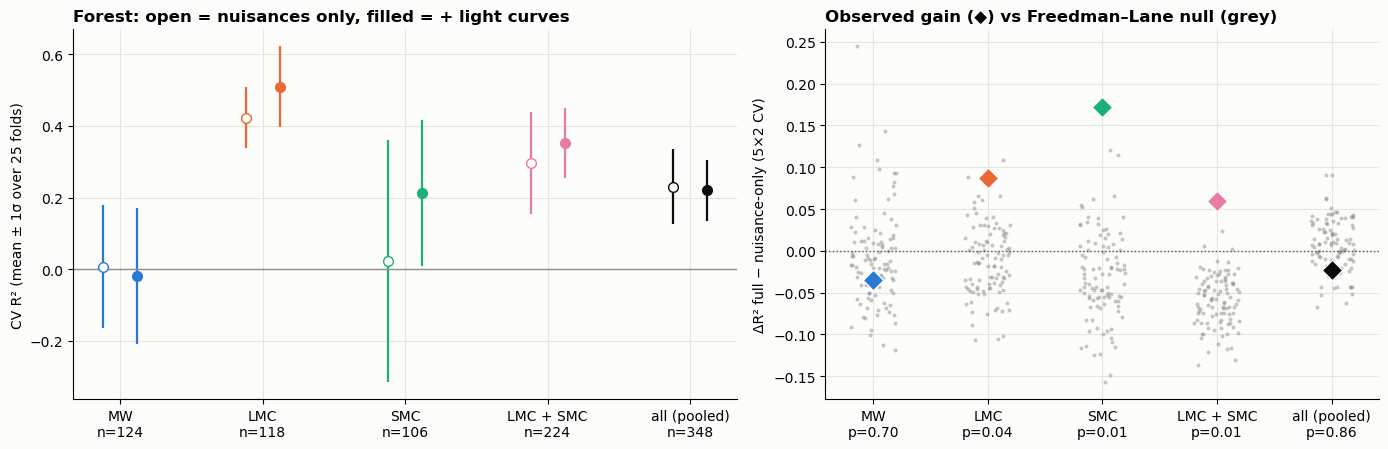

CONCLUSION —
  MW            nuisances +0.007 → full -0.018: gain -0.025 ± 0.133 per fold (null -0.008 ± 0.058, p = 0.70)
  LMC           nuisances +0.423 → full +0.510: gain +0.087 ± 0.064 per fold (null -0.010 ± 0.044, p = 0.04)
  SMC           nuisances +0.022 → full +0.213: gain +0.190 ± 0.200 per fold (null -0.029 ± 0.056, p = 0.01)
  LMC + SMC     nuisances +0.296 → full +0.353: gain +0.056 ± 0.123 per fold (null -0.059 ± 0.030, p = 0.01)
  all (pooled)  nuisances +0.231 → full +0.220: gain -0.011 ± 0.079 per fold (null +0.007 ± 0.031, p = 0.86)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw=dict(width_ratios=[1.2, 1]))
ax = axes[0]
for k, name in enumerate(SUBSETS):
    r = rf_tab.loc[name]
    ax.errorbar(k - .12, r.r2_nuisance, yerr=r.r2_nuisance_sd, fmt='o', mfc='#fcfcfb', color=COL[name], ms=7, elinewidth=1.6)
    ax.errorbar(k + .12, r.r2_full, yerr=r.r2_full_sd, fmt='o', color=COL[name], ms=7, elinewidth=1.6)
ax.axhline(0, color='#8f8e88', lw=1)
ax.set_xticks(range(len(SUBSETS)), [f'{s}\nn={summary.loc[s, "n"]}' for s in SUBSETS])
ax.set_ylabel('CV R² (mean ± 1σ over 25 folds)')
ax.set_title('Forest: open = nuisances only, filled = + light curves', loc='left', fontweight='bold')

ax = axes[1]
for k, name in enumerate(SUBSETS):
    nd = rf_null[name]
    ax.scatter(np.full(len(nd), k) + np.random.default_rng(k).uniform(-.2, .2, len(nd)), nd, s=8, color='#8f8e88', alpha=.5, lw=0)
    ax.scatter(k, rf_tab.loc[name, 'gain_5x2'], s=110, marker='D', color=COL[name], edgecolor='#fcfcfb', zorder=3)
ax.axhline(0, color='#52514e', lw=1, ls=':')
ax.set_xticks(range(len(SUBSETS)), [f'{s}\np={rf_tab.loc[s, "p"]:.2f}' for s in SUBSETS])
ax.set_ylabel('ΔR² full − nuisance-only (5×2 CV)')
ax.set_title('Observed gain (◆) vs Freedman–Lane null (grey)', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

print('CONCLUSION —')
for name, r in rf_tab.iterrows():
    print(f'  {name:<13} nuisances {r.r2_nuisance:+.3f} → full {r.r2_full:+.3f}: gain {r.gain:+.3f} ± {r.gain_sd:.3f} '
          f'per fold (null {r.null_mean:+.3f} ± {r.null_sd:.3f}, p = {r.p:.2f})')

## 4 · Result tables

In [8]:
lin.to_csv('results_by_galaxy_partial.csv', index=False)
lin_tab.to_csv('results_by_galaxy_linear.csv')
rf_tab.to_csv('results_by_galaxy_rf.csv')
both = lin_tab[['n', 'r2_resid', 'p_resid', 'gain', 'p_gain']].rename(
    columns={'gain': 'lin_gain', 'p_gain': 'p_lin_gain'}).join(
    rf_tab[['gain', 'p']].rename(columns={'gain': 'rf_gain', 'p': 'p_rf_gain'}))
both['n_families_sig'] = lin[lin.p_fdr < 0.05].groupby('subset').size().reindex(both.index).fillna(0).astype(int)
display(both.round(3))
print('wrote results_by_galaxy_partial.csv, results_by_galaxy_linear.csv, results_by_galaxy_rf.csv')

print('\nCONCLUSION —')
for name, r in both.iterrows():
    print(f'  {name:<13} n={int(r.n):3d} | families sig {int(r.n_families_sig):2d} | residualized R² {r.r2_resid:+.3f} '
          f'(p {r.p_resid:.3f}) | linear gain {r.lin_gain:+.3f} (p {r.p_lin_gain:.3f}) | '
          f'RF gain {r.rf_gain:+.3f} (p {r.p_rf_gain:.2f})')
print('  Read across rows: a light-curve age signal that is astrophysical should point the same way in')
print('  every galaxy; one carried by a single galaxy is more likely that galaxy\'s systematics.')

,n,r2_resid,p_resid,lin_gain,p_lin_gain,rf_gain,p_rf_gain,n_families_sig
subset,,,,,,,,
MW,124,-0.038,0.060,0.052,0.023,-0.025,0.703,1
LMC,118,-0.037,0.080,0.006,0.023,0.087,0.040,3
SMC,106,-0.119,0.963,-0.033,0.090,0.190,0.010,0
LMC + SMC,224,-0.035,0.578,0.030,0.003,0.056,0.010,4
all (pooled),348,0.007,0.003,0.053,0.003,-0.011,0.861,6


wrote results_by_galaxy_partial.csv, results_by_galaxy_linear.csv, results_by_galaxy_rf.csv

CONCLUSION —
  MW            n=124 | families sig  1 | residualized R² -0.038 (p 0.060) | linear gain +0.052 (p 0.023) | RF gain -0.025 (p 0.70)
  LMC           n=118 | families sig  3 | residualized R² -0.037 (p 0.080) | linear gain +0.006 (p 0.023) | RF gain +0.087 (p 0.04)
  SMC           n=106 | families sig  0 | residualized R² -0.119 (p 0.963) | linear gain -0.033 (p 0.090) | RF gain +0.190 (p 0.01)
  LMC + SMC     n=224 | families sig  4 | residualized R² -0.035 (p 0.578) | linear gain +0.030 (p 0.003) | RF gain +0.056 (p 0.01)
  all (pooled)  n=348 | families sig  6 | residualized R² +0.007 (p 0.003) | linear gain +0.053 (p 0.003) | RF gain -0.011 (p 0.86)
  Read across rows: a light-curve age signal that is astrophysical should point the same way in
  every galaxy; one carried by a single galaxy is more likely that galaxy's systematics.
